# 2026年 衆議院予算委員会 発言トピック・クラスタリング

クリーニング済みの3,453発言を、2016年版と同じSudachiPy、TF-IDF、TruncatedSVD、KMeans（k=10固定）で政策トピック別に分類します。

In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'cleaned').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(ROOT))
from clustering_2016 import (
    FIXED_K, RANDOM_STATE, apply_manual_labels, cluster_details, compare_k,
    export_results, load_input, reduce_dimensions, vectorize,
)

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
INPUT = ROOT / 'cleaned/speeches_2026.jsonl'
OUTPUT_DIR = ROOT / 'analysis/clustering_2026'
print(f'Matplotlib font: {MAC_JAPANESE_FONT} ({mac_font_paths[0]})')
RANDOM_STATE

Matplotlib font: Hiragino Sans (/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc)


42

## 1. 入力検証

件数、会議名、発言IDの一意性、本文の欠損・空文字を検証します。

In [2]:
df = load_input(INPUT, expected_rows=3453)
validation = pd.Series({
    'rows': len(df),
    'unique_speech_ids': df['speechID'].nunique(),
    'meetings': df['nameOfMeeting'].nunique(),
    'missing_cleaned_text': int(df['speech_cleaned'].isna().sum()),
    'empty_cleaned_text': int(df['speech_cleaned'].str.strip().eq('').sum()),
    'review_flagged': int(df['review_flags'].map(bool).sum()),
})
display(validation.to_frame('value'))
display(df[['speechID', 'date', 'speaker', 'speakerPosition', 'speech_cleaned', 'review_flags']].head())

,value
rows,3453
unique_speech_ids,3453
meetings,1
missing_cleaned_text,0
empty_cleaned_text,0
review_flagged,136


,speechID,date,speaker,speakerPosition,speech_cleaned,review_flags
0,122105261X01720260727_000,2026-07-27,会議録情報,None,令和八年七月二十七日（月曜日） 午前九時一分開議 出席委員 委員長 坂本 哲志君 理事 勝俣...,[]
1,122105261X01720260727_004,2026-07-27,武部新,None,自由民主党の武部新です。 質問の機会、ありがとうございます。 まず冒頭、高市総理から提出され...,[]
2,122105261X01720260727_005,2026-07-27,高市早苗,内閣総理大臣,武部委員御指摘のとおり、私は、五月にベトナムにおいて、進化したＦＯＩＰを発表しました。 この...,[]
3,122105261X01720260727_006,2026-07-27,武部新,None,モディ首相も総理のことを美しい妹と呼ばれて、個人的な信頼関係もしっかりと構築できたと評価させ...,[]
4,122105261X01720260727_007,2026-07-27,高市早苗,内閣総理大臣,残念ながら、モディ首相は美しい妹ではなくて妹と言ったということが、ヒンディー語通訳の間違いで...,[]


## 2. 日本語処理、TF-IDF、次元削減

SudachiPyで内容語を正規化し、1〜2語gramのTF-IDFを作成して100次元へ圧縮します。

In [3]:
source_df = df.copy()
vectorizer, tfidf, keep_mask = vectorize(source_df)
zero_vector_records = source_df.loc[~keep_mask].copy()
zero_vector_records['reason'] = 'zero_vector_after_tfidf'
df = source_df.loc[keep_mask].copy().reset_index(drop=True)
svd, reduced = reduce_dimensions(tfidf)
print(f'TF-IDF: {tfidf.shape[0]:,} rows × {tfidf.shape[1]:,} features')
print(f'SVD explained variance: {svd.explained_variance_ratio_.sum():.1%}')
print(f'Zero vectors: {len(zero_vector_records)}')
display(pd.DataFrame({'component': range(1, 11), 'explained_variance': svd.explained_variance_ratio_[:10]}))

TF-IDF: 3,453 rows × 17,683 features
SVD explained variance: 18.2%
Zero vectors: 0


,component,explained_variance
0,1,0.002309
1,2,0.016269
2,3,0.005149
3,4,0.004808
4,5,0.004496
5,6,0.003803
6,7,0.003531
7,8,0.003439
8,9,0.003104
9,10,0.002879


## 3. 10クラスタで学習

クラスタ数を `k=10` に固定し、固定した2,000件標本でsilhouette scoreを確認します。

Fixed k=10


,k,silhouette,inertia,smallest_cluster,largest_cluster
0,10,0.0583,"2,697.3",99,693


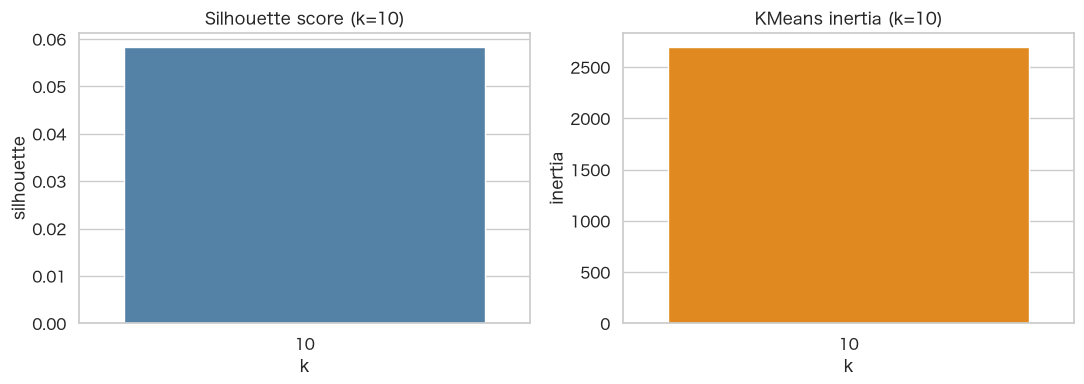

In [4]:
scores, models = compare_k(reduced, candidates=[FIXED_K])
best_k = FIXED_K
model = models[best_k]
print(f'Fixed k={best_k}')
display(scores.style.format({'silhouette': '{:.4f}', 'inertia': '{:,.1f}'}))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=scores, x='k', y='silhouette', color='steelblue', ax=axes[0])
axes[0].set_title('Silhouette score (k=10)')
sns.barplot(data=scores, x='k', y='inertia', color='darkorange', ax=axes[1])
axes[1].set_title('KMeans inertia (k=10)')
plt.tight_layout();

## 4. クラスタの解釈

上位特徴語、重心に近い代表発言、主要話者、月別分布を確認します。

,cluster,provisional_label,count,ratio,top_terms,representative_speech_ids
0,0,日本・投資・成長,406,11.8%,日本 | 投資 | 成長 | 企業 | 経済 | 戦略 | 産業 | 世界 | 我が国 | ai | 作る | 安全,122105261X00220260227_008 | 122105261X00820260309_464 | 122105261X00220260227_010 | 122105261X00720260306_022 | 122105261X00720260306_021
1,1,予算・年度・令和,309,8.9%,予算 | 年度 | 令和 | 令和 年度 | 財政 | 補正 | 補正 予算 | 投資 | 財源 | 当初 | 積極 | 積極 財政,122105261X00520260304_010 | 122105261X00420260303_303 | 122105261X01120260313_082 | 122105261X01120260313_172 | 122105261X01420260604_046
2,2,地域・参る・取り組み,516,14.9%,地域 | 参る | 取り組み | 進める | よる | 自治体 | 致す | 支援 | 行う | 活用 | 確保 | 防災,122105261X00920260311_090 | 122105261X00720260306_012 | 122105261X00920260311_114 | 122105261X00820260309_157 | 122105261X00220260227_073
3,3,負担・制度・子供,393,11.4%,負担 | 制度 | 子供 | 医療 | 見直し | よる | 支援 | 伺う | 医療費 | 致す | 働く | 子育て,122105261X00320260302_241 | 122105261X01020260312_105 | 122105261X00720260306_363 | 122105261X00620260305_025 | 122105261X00820260309_121
4,4,国民 会議・会議・消費税,209,6.1%,国民 会議 | 会議 | 消費税 | 国民 | 給付 | 食料品 | 税額控除 | 給付 税額控除 | 減税 | 議論 | ゼロ | 社会保障,122105261X00220260227_093 | 122105261X00820260309_377 | 122105261X01720260727_124 | 122105261X01520260622_097 | 122105261X00320260302_261
5,5,発言短文・致す 発言短文・参る 発言短文,99,2.9%,発言短文 | 致す 発言短文 | 参る 発言短文 | 伺う 発言短文 | 終了 | 願う | 致す | 調査 | 具体的 目処 | 根拠 | 要求 | 変わる,122105261X01720260727_025 | 122105261X00420260303_160 | 122105261X01120260313_080 | 122105261X00520260304_248 | 122105261X00720260306_308
6,6,価格・備蓄・供給,370,10.7%,価格 | 備蓄 | 供給 | 原油 | 石油 | 影響 | 情勢 | 中東 | 高騰 | 状況 | エネルギー | 物価,122105261X01020260312_185 | 122105261X01120260313_098 | 122105261X01420260604_234 | 122105261X01020260312_181 | 122105261X00820260309_383
7,7,致す・議論・願う,693,20.1%,致す | 議論 | 願う | 宜しい | 調査 | 統一 | よる | 答え | 出る | 情報 | 対する | 自民党,122105261X00320260302_178 | 122105261X01420260604_121 | 122105261X00320260302_180 | 122105261X01020260312_111 | 122105261X01020260312_114
8,8,予算・審議・暫定,156,4.5%,予算 | 審議 | 暫定 | 暫定 予算 | 成立 | 委員会 | 予算 委員会 | 年度内 | 国民 | 国民 生活 | 委員長 | 予算 審議,122105261X01020260312_034 | 122105261X00220260227_292 | 122105261X01120260313_174 | 122105261X00520260304_314 | 122105261X01220260330_009
9,9,イラン・日本・攻撃,302,8.7%,イラン | 日本 | 攻撃 | 事態 | アメリカ | 米国 | 会談 | ホルムズ | 海峡 | ホルムズ 海峡 | 国連 | 外交,122105261X00520260304_058 | 122105261X01220260330_060 | 122105261X00420260303_154 | 122105261X01020260312_128 | 122105261X01220260330_062


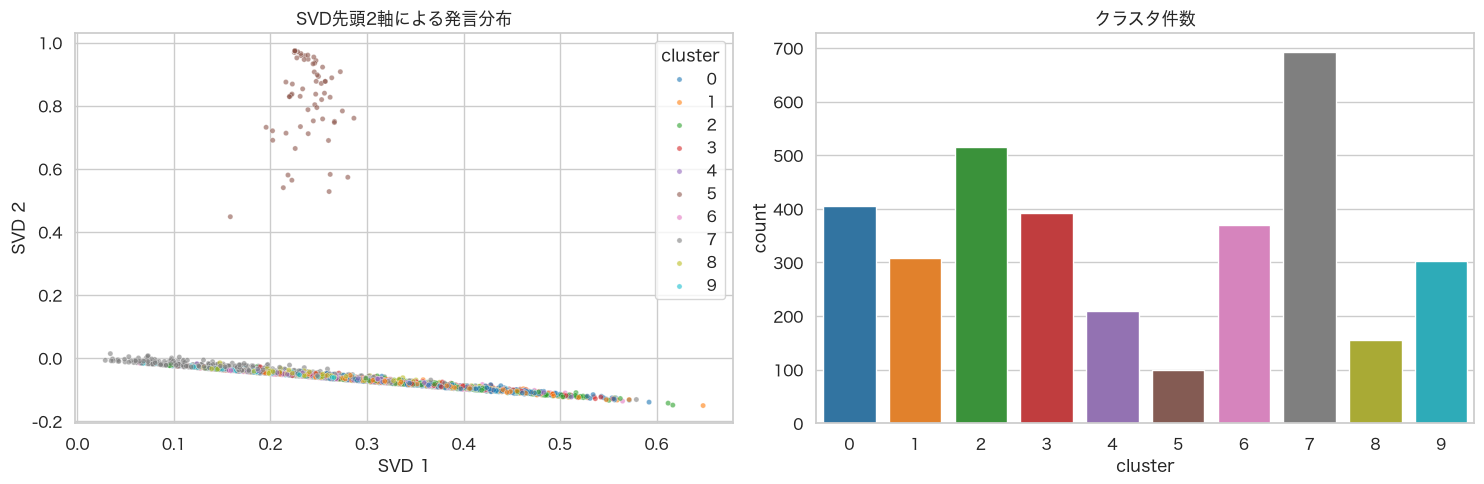

In [5]:
assignments, summary = cluster_details(df, tfidf, reduced, vectorizer, model)
display(summary.style.format({'ratio': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=reduced[:, 0], y=reduced[:, 1], hue=assignments['cluster'], palette='tab10', s=14, alpha=.6, legend='full', ax=axes[0])
axes[0].set(title='SVD先頭2軸による発言分布', xlabel='SVD 1', ylabel='SVD 2')
sns.barplot(data=summary, x='cluster', y='count', hue='cluster', palette='tab10', legend=False, ax=axes[1])
axes[1].set_title('クラスタ件数')
plt.tight_layout();

In [6]:
for cluster_id in summary['cluster']:
    row = summary.loc[summary['cluster'].eq(cluster_id)].iloc[0]
    members = assignments.loc[assignments['cluster'].eq(cluster_id)]
    representatives = members.nsmallest(5, 'centroid_distance')[['speechID', 'date', 'speaker', 'speech_cleaned', 'centroid_distance']]
    top_speakers = members['speaker'].value_counts().head(5).rename_axis('speaker').reset_index(name='count')
    print(f"\nCluster {cluster_id}: {row['provisional_label']} ({row['count']:,}件)")
    print(f"特徴語: {row['top_terms']}")
    display(top_speakers, representatives)


Cluster 0: 日本・投資・成長 (406件)
特徴語: 日本 | 投資 | 成長 | 企業 | 経済 | 戦略 | 産業 | 世界 | 我が国 | ai | 作る | 安全


,speaker,count
0,高市早苗,50
1,赤澤亮正,23
2,高山聡史,21
3,片山さつき,14
4,村岡敏英,13


,speechID,date,speaker,speech_cleaned,centroid_distance
3141,122105261X00220260227_008,2026-02-27,小林鷹之,ありがとうございます。 昨日、自民党としても実質的に提言を取りまとめたところでありますので、...,0.680850
1670,122105261X00820260309_464,2026-03-09,鈴木厚人,本日は、このような意見を述べる機会を与えていただきまして、ありがとうございます。 私が配らせ...,0.695385
3143,122105261X00220260227_010,2026-02-27,小林鷹之,いずれも重要だというのはそのとおりだと思います。その中でもやはり優先順位というものを一定程度...,0.726257
1765,122105261X00720260306_022,2026-03-06,鈴木憲和,御質問ありがとうございます。 委員が川崎市の企業に行っていただいたところでありますが、私も何...,0.731691
1764,122105261X00720260306_021,2026-03-06,野中厚,今答弁の中で取り上げていただいたプロモーション活動ですけれども、やはり、輸出している事業者か...,0.738225



Cluster 1: 予算・年度・令和 (309件)
特徴語: 予算 | 年度 | 令和 | 令和 年度 | 財政 | 補正 | 補正 予算 | 投資 | 財源 | 当初 | 積極 | 積極 財政


,speaker,count
0,高市早苗,63
1,片山さつき,43
2,上野賢一郎,13
3,階猛,12
4,高山聡史,12


...

,speaker,count
0,高市早苗,27
1,片山さつき,17
2,後藤祐一,15
3,近藤和也,10
4,階猛,10


,speechID,date,speaker,speech_cleaned,centroid_distance
900,122105261X01020260312_034,2026-03-12,階猛,国民生活の安心のためという言葉がありまして、それに対しては私たちも思うところは一緒であります...,0.612703
3406,122105261X00220260227_292,2026-02-27,後藤祐一,是非、これは大事ですからやってください。逆に、当初予算を増やしました、補正もやはり同じように...,0.639605
868,122105261X01120260313_174,2026-03-13,長友慎治,国民民主党の長友慎治です。 私は、会派を代表し、ただいま議題となりました令和八年度総予算に反...,0.642047
2545,122105261X00520260304_314,2026-03-04,向山好一,もう時間が来ましたので、要望にさせていただきたいと思いますけれども。 先ほどから総務大臣はず...,0.644372
581,122105261X01220260330_009,2026-03-30,階猛,過去にもそういう例はあり、今回もそのようにしたということなんですね。 我々も、衆議院での予算...,0.647156



Cluster 9: イラン・日本・攻撃 (302件)
特徴語: イラン | 日本 | 攻撃 | 事態 | アメリカ | 米国 | 会談 | ホルムズ | 海峡 | ホルムズ 海峡 | 国連 | 外交


,speaker,count
0,高市早苗,63
1,茂木敏充,46
2,長妻昭,19
3,後藤祐一,18
4,小泉進次郎,18


,speechID,date,speaker,speech_cleaned,centroid_distance
2323,122105261X00520260304_058,2026-03-04,河西宏一,おはようございます。中道の河西宏一でございます。どうぞよろしくお願いをいたします。 先ほど我...,0.688729
628,122105261X01220260330_060,2026-03-30,伊佐進一,日本として、本当にこの事態において主体的に、国際的なこの大きな事態に対して、課題解決に向けて...,0.705435
2709,122105261X00420260303_154,2026-03-03,山崎正恭,中道改革連合の山崎正恭です。 私が最後のバッターになります。よろしくお願いいたします。 まず...,0.705813
983,122105261X01020260312_128,2026-03-12,吉田宣弘,ダイレクトにお聞かせいただきます。 現時点においてです。やはり情勢は刻々と変化しますので、現...,0.711645
630,122105261X01220260330_062,2026-03-30,伊佐進一,私は、もう少し目に見える形で、とりわけトップ外交が大事だと思っておりまして、総理がもう少しト...,0.721462


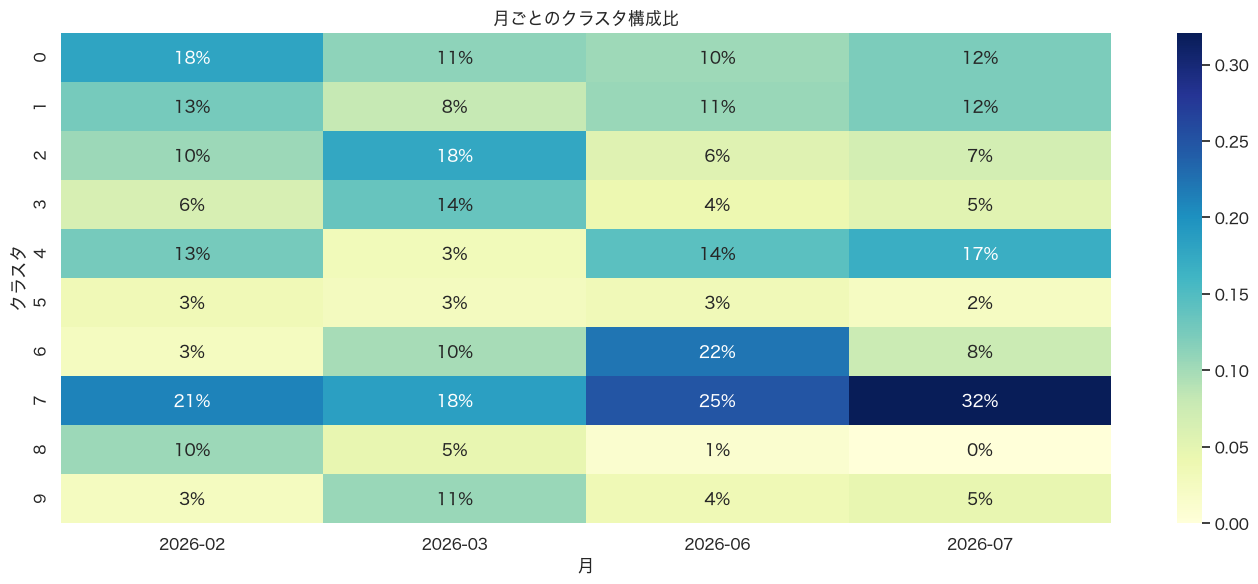

In [7]:
monthly = pd.crosstab(assignments['month'], assignments['cluster'], normalize='index')
plt.figure(figsize=(14, 6))
sns.heatmap(monthly.T, cmap='YlGnBu', annot=True, fmt='.0%')
plt.title('月ごとのクラスタ構成比')
plt.xlabel('月')
plt.ylabel('クラスタ')
plt.tight_layout();

## 5. 人手によるラベル調整

代表発言を確認し、必要なクラスタだけ辞書へ名称を追加してください。

In [ ]:
MANUAL_CLUSTER_LABELS = {
    # 0: '社会保障・医療',
    # 1: '外交・安全保障',
}
assignments, summary = apply_manual_labels(assignments, summary, MANUAL_CLUSTER_LABELS)
display(summary[['cluster', 'cluster_label', 'count', 'ratio', 'top_terms']].style.format({'ratio': '{:.1%}'}))

## 6. CSV出力と最終検証

UTF-8 BOM付きで発言別結果とクラスタ要約を保存します。

In [ ]:
assert len(assignments) == len(df)
assert assignments['cluster'].notna().all()
assert set(assignments['cluster']) == set(range(best_k))
assert summary['count'].sum() == len(df)
assert best_k == 10
assert len(scores) == 1
export_results(assignments, summary, OUTPUT_DIR)
clusters_path = OUTPUT_DIR / 'speech_clusters.csv'
summary_path = OUTPUT_DIR / 'cluster_summary.csv'
assert len(pd.read_csv(clusters_path)) == len(df)
assert len(pd.read_csv(summary_path)) == best_k
print(f'発言別結果: {clusters_path}')
print(f'クラスタ要約: {summary_path}')
print(f'検証完了: {len(assignments):,}件、{best_k}クラスタ')